# ML Lab
# Lab - 6
## Name :- Jaheed Pathan
## Roll no :- 53
## Section :- A-A4

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import Input, Dense

In [2]:
df = pd.read_csv("seeds_new (1).csv")

In [3]:
print(df.head())

    Area  Perimeter  Compactness  Length of kernel  Width of kernel  \
0  15.26      14.84       0.8710             5.763            3.312   
1  14.88      14.57       0.8811             5.554            3.333   
2  14.29      14.09       0.9050             5.291            3.337   
3  13.84      13.94       0.8955             5.324            3.379   
4  16.14      14.99       0.9034             5.658            3.562   

   Asymmetry coefficient  Length of kernel groove  Class (1, 2, 3) Unnamed: 8  \
0                  2.221                    5.220                1        NaN   
1                  1.018                    4.956                1        NaN   
2                  2.699                    4.825                1        NaN   
3                  2.259                    4.805                1        NaN   
4                  1.355                    5.175                1        NaN   

  Unnamed: 9  
0        NaN  
1        NaN  
2        NaN  
3        NaN  
4        Na

In [4]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3,NaN,NaN
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3,NaN,NaN
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3,NaN,NaN
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3,NaN,NaN
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3,NaN,NaN


In [5]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)",Unnamed: 8,Unnamed: 9
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1,NaN,NaN
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1,NaN,NaN
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1,NaN,NaN
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1,NaN,NaN
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1,NaN,NaN


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
 8   Unnamed: 8               2 non-null      object 
 9   Unnamed: 9               1 non-null      object 
dtypes: float64(7), int64(1), object(2)
memory usage: 16.5+ KB


In [7]:
df.describe()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [8]:
df.isnull().sum()

,0
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1, 2, 3)",0
Unnamed: 8,208
Unnamed: 9,209


In [9]:
df.shape

(210, 10)

In [10]:
df.shape[0]

210

In [11]:
df.shape[1]

10

In [12]:
df=df.dropna(axis=1,how="all")

In [13]:
df=df.loc[:,~df.columns.str.startswith("Unnamed")]

In [14]:
X=df.drop("Class (1, 2, 3)",axis=1)
y_original=df["Class (1, 2, 3)"]
print("Input shape",X.shape)
print("Target shape",y_original.shape)

Input shape (210, 7)
Target shape (210,)


In [15]:
y=y_original-1
print("original classes:")
print(sorted(y_original.unique()))
print("\nANN encoded classes:")
print(sorted(y.unique()))

original classes:
[np.int64(1), np.int64(2), np.int64(3)]

ANN encoded classes:
[np.int64(0), np.int64(1), np.int64(2)]


In [16]:
X_train ,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("training samples:",X_train.shape[0])
print("testing samples:",X_test.shape[0])

training samples: 168
testing samples: 42


In [17]:
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [18]:
scaler.fit_transform(X_test)

array([[-0.13481356, -0.30885661,  1.63834475, -0.72108928,  0.28326462,
        -0.76430253, -1.20943602],
       [-0.86696115, -0.79265998, -1.079508  , -0.44412568, -1.01611436,
        -0.08296069, -0.1493714 ],
       [ 0.3031065 ,  0.49244271, -0.70339658,  0.66153059,  0.00779627,
        -0.80711315,  0.9685525 ],
       [-1.32882996, -1.4578896 , -0.42131302, -1.40250766, -1.05769449,
         0.74059948, -0.71763216],
       [ 1.23710786,  1.05184035,  1.89804073,  0.79121989,  1.36954545,
        -0.66416923,  1.14006393],
       [-0.46667485, -0.42224803, -0.31833013, -0.17155833, -0.40280748,
         2.38191499,  0.06140168],
       [ 2.15058173,  2.0799225 ,  0.78313902,  2.07492419,  1.98285233,
         0.67094153,  1.87157051],
       [ 0.37495276,  0.31101645,  1.0697001 ,  0.12079214,  0.53534414,
         1.33559449, -0.56678476],
       [ 1.65107916,  1.67171341,  0.42941519,  1.6418938 ,  1.48908831,
        -0.57346877,  1.60087175],
       [ 1.28842662,  1.2257

In [19]:
print("first 5 scaled trtaining samples:")
print(X_train_scaled[:5])

first 5 scaled trtaining samples:
[[-1.17682401 -1.1750583  -1.02169157 -1.02785725 -1.35751947  1.43188942
  -0.82441016]
 [-0.87298429 -1.06714618  0.86676795 -1.26492983 -0.59897345 -0.3056117
  -1.63150367]
 [-0.12719589  0.01968295 -0.66917913  0.25096694 -0.40933695 -1.4432301
   0.1615857 ]
 [-1.29421662 -1.37546651 -0.66498255 -1.41310019 -1.26136575  1.7668294
  -0.72886004]
 [-0.58295547 -0.70486981  0.69890488 -0.90020279 -0.09149548  3.02743357
  -0.71462918]]


In [20]:
model=Sequential([
    Input(shape=(7,)),
    Dense(16,activation="relu"),
    Dense(8,activation="relu"),
    Dense(3,activation="softmax")
])

In [21]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
model.compile(
    optimizer =Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [23]:
loss="sparse_categorical_crossentropy"

In [24]:
early_stop=EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [25]:
history=model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 4s 214ms/step - accuracy: 0.0149 - loss: 1.3411 - val_accuracy: 0.0588 - val_loss: 1.2887
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.0224 - loss: 1.2186 - val_accuracy: 0.0294 - val_loss: 1.1804
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.1493 - loss: 1.1202 - val_accuracy: 0.2059 - val_loss: 1.0838
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.2687 - loss: 1.0363 - val_accuracy: 0.2941 - val_loss: 1.0022
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step - accuracy: 0.3358 - loss: 0.9647 - val_accuracy: 0.4706 - val_loss: 0.9354
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 38ms/step - accuracy: 0.4328 - loss: 0.9056 - val_accuracy: 0.5882 - val_loss: 0.8819
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.5821 - loss: 0.8564 - val_accuracy: 0.6471 - val_loss: 0.8400
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.6866 - loss: 0.8176 - val_accuracy: 0.7353 - val_loss

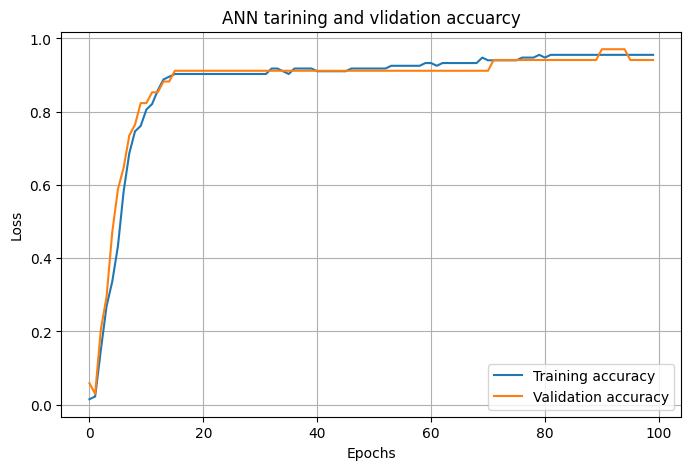

In [26]:
plt.figure(figsize=(8,5))
plt.plot(history.history["accuracy"],label="Training accuracy")
plt.plot(history.history["val_accuracy"],label="Validation accuracy")
plt.title("ANN tarining and vlidation accuarcy")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

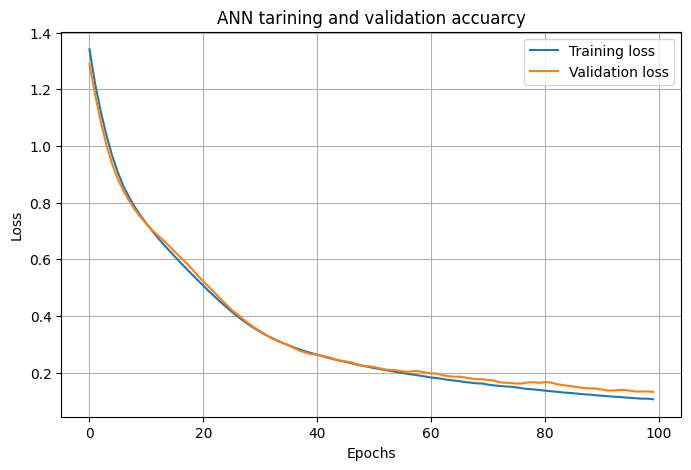

In [27]:
plt.figure(figsize=(8,5))
plt.plot(history.history["loss"],label="Training loss")
plt.plot(history.history["val_loss"],label="Validation loss")
plt.title("ANN tarining and validation accuarcy")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
test_loss,test_accuracy=model.evaluate(X_test_scaled,y_test,verbose=1)
print("Test loss:",test_loss)
print("test accuracy",test_accuracy)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.8810 - loss: 0.2723
Test loss: 0.2723153531551361
test accuracy 0.8809523582458496


In [29]:
y_prob=model.predict(X_test_scaled,verbose=1)
print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
[[9.7852606e-01 1.0167257e-02 1.1306598e-02]
 [6.1322641e-02 8.2016122e-03 9.3047565e-01]
 [3.6219338e-01 6.2850547e-01 9.3010515e-03]
 [1.9583881e-03 1.3117149e-03 9.9672979e-01]
 [1.2071765e-03 9.9878269e-01 1.0115428e-05]]


In [30]:
y_pred=np.argmax(y_prob,axis=1)
print("predicted encoded classes:")
print(y_pred[:10])

predicted encoded classes:
[0 2 1 2 1 2 1 1 1 1]


In [31]:
y_pred_original=y_pred+1
y_test_original=y_test+1
print("predicted classes:")
print(y_pred_original[:10])

predicted classes:
[1 3 2 3 2 3 2 2 2 2]


In [32]:
comparison=pd.DataFrame({
    "actual":y_test_original.values,
    "predicted":y_pred_original
})
comparison.head(15)

,actual,predicted
0,1,1
1,3,3
2,2,2
3,3,3
4,2,2
5,3,3
6,2,2
7,1,2
8,2,2
9,2,2


In [33]:
accuracy=accuracy_score(y_test_original,y_pred_original)
print("accuracy:",accuracy)

accuracy: 0.8809523809523809


In [34]:
precision=precision_score(y_test_original,y_pred_original,average='weighted')
print("precision:",precision)

precision: 0.8995098039215687


In [35]:
recall=recall_score(y_test_original,y_pred_original,average='weighted')
print("recall:",recall)

recall: 0.8809523809523809


In [36]:
f1=f1_score(y_test_original,y_pred_original,average='weighted')
print("f1:",f1)

f1: 0.8730559451457066


In [39]:
print(classification_report(y_test_original,y_pred_original))

              precision    recall  f1-score   support

           1       1.00      0.64      0.78        14
           2       0.82      1.00      0.90        14
           3       0.88      1.00      0.93        14

    accuracy                           0.88        42
   macro avg       0.90      0.88      0.87        42
weighted avg       0.90      0.88      0.87        42



In [37]:
cm=confusion_matrix(y_test_original,y_pred_original)
print(cm)

[[ 9  3  2]
 [ 0 14  0]
 [ 0  0 14]]


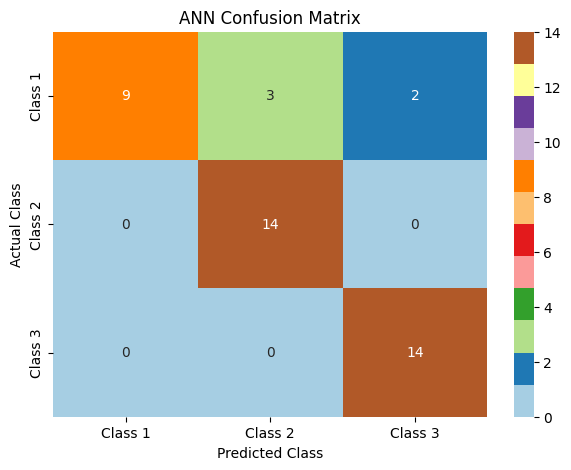

In [42]:
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Paired",
            xticklabels=["Class 1", "Class 2", "Class 3"],
            yticklabels=["Class 1", "Class 2", "Class 3"])
plt.title("ANN Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.show()